<a href="https://colab.research.google.com/github/shivamkumar359/03-rd-SEM--ASSIGNMENTS/blob/main/OS/W_9_PRACTICAL_ASSIGNMENT_TASK_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# CIA TRIAD SIMULATOR
# Access Control and File Permissions

print("=" * 50)
print("       CIA TRIAD ACCESS CONTROL SIMULATOR")
print("=" * 50)

# Define users
users = ['admin', 'student', 'faculty']

# Define files and their permissions
files = {
    'student_grades.txt': {
        'authorized_readers': ['admin', 'faculty'],
        'authorized_writers': ['admin', 'faculty']
    },

    'admin_config.txt': {
        'authorized_readers': ['admin'],
        'authorized_writers': ['admin']
    },

    'shared_notes.txt': {
        'authorized_readers': ['admin', 'student', 'faculty'],
        'authorized_writers': ['admin', 'student', 'faculty']
    },

    'exam_paper.txt': {
        'authorized_readers': ['admin'],
        'authorized_writers': ['admin']
    }
}

print("\nFiles registered successfully!")

for filename in files:
    print("-", filename)

       CIA TRIAD ACCESS CONTROL SIMULATOR

Files registered successfully!
- student_grades.txt
- admin_config.txt
- shared_notes.txt
- exam_paper.txt


In [2]:
def check_access(username, filename, action):

    if filename not in files:
        print("ACCESS DENIED: File does not exist.")
        return False

    if username not in users:
        print("ACCESS DENIED: Unknown user.")
        return False

    if action == "read":
        authorized = files[filename]['authorized_readers']

    elif action == "write":
        authorized = files[filename]['authorized_writers']

    else:
        print("INVALID ACTION")
        return False

    if username in authorized:
        print(f"ACCESS GRANTED: {username} can {action} {filename}")
        return True

    else:
        print(f"ACCESS DENIED: {username} cannot {action} {filename}")
        return False

In [3]:
print("CIA TRIAD ACCESS CONTROL TEST")
print("-" * 40)

check_access("admin", "exam_paper.txt", "read")

check_access("admin", "exam_paper.txt", "write")

check_access("student", "exam_paper.txt", "read")

check_access("student", "exam_paper.txt", "write")

check_access("faculty", "exam_paper.txt", "read")

CIA TRIAD ACCESS CONTROL TEST
----------------------------------------
ACCESS GRANTED: admin can read exam_paper.txt
ACCESS GRANTED: admin can write exam_paper.txt
ACCESS DENIED: student cannot read exam_paper.txt
ACCESS DENIED: student cannot write exam_paper.txt
ACCESS DENIED: faculty cannot read exam_paper.txt


False

In [4]:
import pandas as pd

scenarios = [
    ("Admin reads exam paper", "admin", "read", "exam_paper.txt"),
    ("Admin writes exam paper", "admin", "write", "exam_paper.txt"),
    ("Student reads exam paper", "student", "read", "exam_paper.txt"),
    ("Student writes exam paper", "student", "write", "exam_paper.txt"),
    ("Faculty reads exam paper", "faculty", "read", "exam_paper.txt")
]

results = []

for description, username, action, filename in scenarios:

    allowed = (
        username in files[filename][
            "authorized_readers" if action == "read"
            else "authorized_writers"
        ]
    )

    results.append({
        "Scenario": description,
        "User": username,
        "Action": action,
        "File": filename,
        "Result": "Granted" if allowed else "Denied"
    })

df = pd.DataFrame(results)

display(df)

print("Successful attempts:", (df["Result"] == "Granted").sum())
print("Denied attempts:", (df["Result"] == "Denied").sum())

,Scenario,User,Action,File,Result
0,Admin reads exam paper,admin,read,exam_paper.txt,Granted
1,Admin writes exam paper,admin,write,exam_paper.txt,Granted
2,Student reads exam paper,student,read,exam_paper.txt,Denied
3,Student writes exam paper,student,write,exam_paper.txt,Denied
4,Faculty reads exam paper,faculty,read,exam_paper.txt,Denied


Successful attempts: 2
Denied attempts: 3


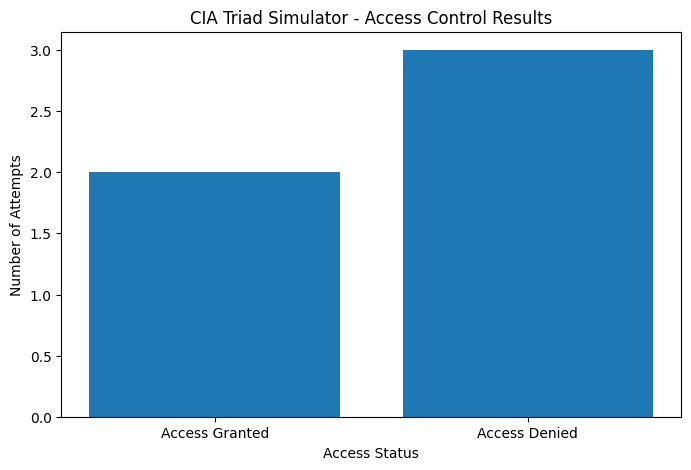

Access Granted: 2
Access Denied: 3
Chart saved as access_results.png


In [5]:
import matplotlib.pyplot as plt

# Count access results
granted = (df["Result"] == "Granted").sum()
denied = (df["Result"] == "Denied").sum()

# Generate bar chart
plt.figure(figsize=(8, 5))

plt.bar(
    ["Access Granted", "Access Denied"],
    [granted, denied]
)

plt.title("CIA Triad Simulator - Access Control Results")
plt.xlabel("Access Status")
plt.ylabel("Number of Attempts")

plt.savefig("access_results.png", dpi=300, bbox_inches="tight")

plt.show()

print("Access Granted:", granted)
print("Access Denied:", denied)
print("Chart saved as access_results.png")

In [6]:
from google.colab import files as colab_files

colab_files.download("access_results.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

The CIA Triad Simulator uses Access Control Lists (ACLs) to manage file permissions. Each file has a list of authorized readers and writers. When a user requests to read or write a file, the simulator checks whether that user is included in the corresponding authorization list. If the user is authorized, access is granted; otherwise, access is denied. For example, only the admin can read or modify exam_paper.txt, while students and faculty members are denied access. This mechanism helps maintain confidentiality, prevent unauthorized modifications, and protect sensitive information.